# Traveling-wave analysis of macaque motor-cortex recordings

This notebook detects and characterizes traveling-wave episodes in local field potential (LFP) recordings from macaque motor cortex. It loads electrophysiological and behavioral data, extracts trial-aligned windows, and estimates wave occurrence, propagation direction, speed, and wavelength.

## Data setup

Download this repository and the experimental data from Zenodo. Create a folder named Macaque_data alongside this notebook and place both input files inside it:

Beh_matrix.mat

rs1050225_MI_clean_LFP.mat

Run Jupyter from the directory containing the notebook. If you store the data elsewhere, update DATA_DIR in the configuration cell to point to that folder.

## Preprocessing and phase estimation

LFP signals are normalized within each trial and mapped onto the electrode grid. Missing or excluded channels are reconstructed by spatial interpolation of the LFP traces, with nearest-neighbor filling outside the observed convex hull.

The analysis band is specified manually or selected around the dominant frequency in the mean Welch power spectrum across retained channels and trials. Signals are bandpass-filtered using additional temporal context around each trial to reduce edge effects. Instantaneous phase is then obtained from the Hilbert transform and unwrapped along both spatial axes before calculating spatial phase gradients. Each trial is analysed independently.

## Traveling-wave detection

Spatial coherence is quantified using **phase-gradient directionality (PGD)**:

$$
\mathrm{PGD}(t)
=
\frac{\left\|\left\langle \nabla\phi(t)\right\rangle\right\|}
{\left\langle\left\|\nabla\phi(t)\right\|\right\rangle},
$$

where $\phi$ is the instantaneous phase and angle brackets denote an average over grid sites. PGD approaches 1 when spatial phase gradients point in a common direction and decreases when they cancel across the array.

A traveling-wave episode is defined as a continuous interval during which PGD exceeds `FIXED_R_THRESHOLD` for at least `MIN_WAVE_DURATION_MS`. The current settings use **PGD > 0.5 for at least 10 ms**. Despite its name, `FIXED_R_THRESHOLD` applies to PGD. No plane-fit residual threshold is used for detection.

## Wave characteristics

For each detected episode, the notebook estimates:

- **Direction:** At each valid frame, the propagation direction is taken opposite to the spatially averaged phase gradient. These frame directions are combined using a circular mean to obtain one direction per episode. This convention assumes positive temporal phase progression.
- **Speed:** Framewise speed is calculated as the absolute temporal phase derivative divided by the spatial mean of the phase-gradient magnitude. The temporal derivative is estimated from temporally unwrapped phase and summarized by its median across grid sites.
- **Wavelength:** The episode wavelength is calculated as $2\pi$ divided by the magnitude of the phase gradient averaged over space and over the episode.

A minimum gradient magnitude excludes poorly defined speed and direction estimates. Speeds are reported in cm/s and wavelengths in cm. The output includes both framewise speeds pooled across detected episodes and one mean speed per episode.

## Outputs and configuration

Results are exported to a MATLAB-compatible `.mat` file containing event-level measurements, trial-level diagnostics, and analysis settings. Summary plots show the detected wave characteristics.

Input paths, trial windows, electrode spacing, frequency-band settings, detection threshold, and minimum episode duration are specified in the configuration cell.

Find the exported .mat results in the folder "results".

In [10]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat, savemat
from scipy.interpolate import LinearNDInterpolator
from scipy.spatial import cKDTree

DATA_DIR = Path("Macaque_data")
OUTPUT_DIR = Path("results")
LFP_FILENAME = "rs1050225_MI_clean_LFP.mat"
BEHAVIOR_FILENAME = "Beh_matrix.mat"
NUMBER_TRIALS = 300
# DURATION_MS = 1200
# PRE_ONSET_MS = 200

MANUAL_BAND_HZ = None #(10.0, 45.0)
PRE_ONSET_MS = 0
DURATION_MS = 800

GRID_SIDE = 10
ELECTRODE_SPACING_MM = 0.4
EXCLUDED_CHANNELS_MATLAB = [2, 25, 66, 67, 74]  # 1-based lfp-variable indices
CHANNEL_NAMES = None  # Optional explicit ordered list matching MIchan2rc rows.
LFP_SAMPLE_INTERVAL_MS = 1.0
FILTER_ORDER = 4
FILTER_CONTEXT_MS = 1000
BAND_SEARCH_HZ = (11.0, 30.0)
BAND_HALF_WIDTH_HZ = 3.0
 
FIXED_R_THRESHOLD = 0.5  # Now applies to PGD, not unit-gradient r
 
MIN_WAVE_DURATION_MS = 10.0
MIN_GRADIENT_MM_INV = 1e-3

N_DIRECTION_BINS = 15

BAND_SEARCH_HZ = (10.0, 50.0)
BAND_LIMITS_HZ = (10.0, 30.0)
BAND_HALF_WIDTH_HZ = 3.0
 

In [11]:
def load_inputs():

    missing = [
    name for name in (LFP_FILENAME, BEHAVIOR_FILENAME)
    if not (DATA_DIR / name).is_file()
    ]
    if missing:
        raise FileNotFoundError(
            f"Missing files: {', '.join(missing)}\n"
            f"Expected folder: {DATA_DIR.resolve()}\n"
            "Download the experimental data from "
            "https://doi.org/10.5281/zenodo.19420479 "
            "and place both MAT files in this folder, "
            "or update DATA_DIR in the configuration cell."
        )

    try:
        mat = loadmat(DATA_DIR / LFP_FILENAME)
        behavior = loadmat(DATA_DIR / BEHAVIOR_FILENAME)
    except NotImplementedError as exc:
        raise ValueError("These files use MATLAB v7.3/HDF5; this notebook needs standard MAT files.") from exc
    names = list(CHANNEL_NAMES) if CHANNEL_NAMES is not None else [k for k in mat if k.startswith("lfp")]
    if not names or "MIchan2rc" not in mat or "beh" not in behavior:
        raise ValueError("Expected lfp* variables, MIchan2rc, and beh.")
    coords = np.asarray(mat["MIchan2rc"], dtype=float)
    if coords.ndim != 2 or coords.shape[1] != 2 or len(coords) < len(names):
        raise ValueError("MIchan2rc must contain one [row, column] per LFP channel.")
    coords = coords[:len(names)]
    if not np.all(np.isfinite(coords)) or not np.all(coords == np.round(coords)):
        raise ValueError("Grid coordinates must be finite integer indices.")
    coords = coords.astype(int) - 1
    if np.any(coords < 0) or np.any(coords >= GRID_SIDE) or len(np.unique(coords, axis=0)) != len(coords):
        raise ValueError("Invalid or duplicate grid positions.")
    excluded = np.asarray(EXCLUDED_CHANNELS_MATLAB, dtype=int) - 1
    if np.any(excluded < 0) or np.any(excluded >= len(names)):
        raise ValueError("An excluded channel index is outside the available LFP channels.")
    keep = [i for i in range(len(names)) if i not in set(excluded)]
    vectors = [np.asarray(mat[names[i]], dtype=float).reshape(-1) for i in keep]
    if len({len(v) for v in vectors}) != 1:
        raise ValueError("LFP channel lengths differ.")
    data = np.column_stack(vectors)
    if not np.all(np.isfinite(data)):
        raise ValueError("Retained LFP channels contain NaN/Inf; inspect channel exclusion.")
    beh = np.asarray(behavior["beh"], dtype=float)
    if beh.ndim != 2 or beh.shape[1] < 1 or not 2 <= NUMBER_TRIALS <= len(beh):
        raise ValueError("NUMBER_TRIALS must be between 2 and the number of behavioral rows.")
    if int(NUMBER_TRIALS) != NUMBER_TRIALS:
        raise ValueError("NUMBER_TRIALS must be an integer.")
    print(f"Loaded {data.shape[0]} samples, {data.shape[1]} retained channels.")
    print("Verify this variable order against MIchan2rc:", names)
    return data, coords[keep], beh, [names[i] for i in keep]


def trial_windows(beh, n_samples):
    fs = 1000.0 / LFP_SAMPLE_INTERVAL_MS
    n_duration = DURATION_MS / LFP_SAMPLE_INTERVAL_MS
    n_pre = PRE_ONSET_MS / LFP_SAMPLE_INTERVAL_MS
    if n_duration != round(n_duration) or n_pre != round(n_pre):
        raise ValueError("Trial duration and offset must align with sample times.")
    windows = []
    for trial in range(NUMBER_TRIALS):
        onset = beh[trial, 0]
        if not np.isfinite(onset):
            raise ValueError(f"Trial {trial+1}: nonfinite onset.")
        # Match MATLAB's max(1, floor(onset*fs)-200), then convert to 0-based.
        start = max(1, int(np.floor(onset*fs)) - int(n_pre)) - 1
        stop = start + int(n_duration)
        if not 0 <= start < stop <= n_samples:
            raise ValueError(f"Trial {trial+1}: complete requested window unavailable.")
        windows.append((start, stop))
    return windows




def zscore_channels(values, reference):
    """Normalize using the mean and SD of the analysis window."""
    mean = reference.mean(axis=0, keepdims=True)
    std = reference.std(axis=0, keepdims=True)

    if np.any(~np.isfinite(std)) or np.any(std == 0):
        raise ValueError("A channel has invalid or zero SD in this trial.")

    return (values - mean) / std
    
def choose_band(data, windows):
    fs = 1000.0 / LFP_SAMPLE_INTERVAL_MS
    nperseg = min(1000, min(b-a for a,b in windows))
    if nperseg < 4:
        raise ValueError("Trial windows too short for PSD.")
    mean_psd = None
    for start, stop in windows:
        segment = data[start:stop]
        segment = zscore_channels(segment, segment)
        
        freq, psd = signal.welch(
            segment,
            fs=fs,
            nperseg=nperseg,
            noverlap=nperseg // 2,
            nfft=max(2048, nperseg),
            axis=0,
        )
        p = psd.mean(axis=1)
        mean_psd = p if mean_psd is None else mean_psd + p
    mean_psd /= len(windows)
    use = (freq >= BAND_SEARCH_HZ[0]) & (freq <= BAND_SEARCH_HZ[1])
    if not np.any(use):
        raise ValueError("No PSD bins in BAND_SEARCH_HZ.")
    peak = float(freq[use][np.argmax(mean_psd[use])])


    band = tuple(MANUAL_BAND_HZ) if MANUAL_BAND_HZ is not None else (
    max(BAND_LIMITS_HZ[0], peak - BAND_HALF_WIDTH_HZ),
    min(BAND_LIMITS_HZ[1], peak + BAND_HALF_WIDTH_HZ))
    
    if not 0 < band[0] < band[1] < fs/2:
        raise ValueError(f"Invalid band {band}.")
    return peak, band, freq, mean_psd


def interpolation_weights(coords):
    # Grid in row-major order, consistent with reshape(time, rows, columns).
    yy, xx = np.mgrid[:GRID_SIDE, :GRID_SIDE]
    target = np.column_stack((yy.ravel(),xx.ravel()))
    weights = np.asarray(LinearNDInterpolator(coords, np.eye(len(coords)))(target))
    missing = ~np.all(np.isfinite(weights),axis=1)
    nearest = cKDTree(coords).query(target[missing])[1]
    weights[missing] = np.eye(len(coords))[nearest]
    # Preserve measured sites exactly.
    weights[coords[:,0]*GRID_SIDE+coords[:,1]] = np.eye(len(coords))
    return weights


In [3]:
def plane_design(n_side):
    x_mm, y_mm = np.meshgrid(
        np.arange(n_side) * ELECTRODE_SPACING_MM,
        np.arange(n_side) * ELECTRODE_SPACING_MM,
    )
    design = np.column_stack((x_mm.ravel(), y_mm.ravel(), np.ones(n_side**2)))
    return design, np.linalg.pinv(design)

def phase_metrics(phases, design, pinv_design):
    """Spatial unit-gradient resultant r, residual, and plane-fit slopes."""
    grad_y, grad_x = np.gradient(
        phases,
        ELECTRODE_SPACING_MM,
        ELECTRODE_SPACING_MM,
        axis=(1, 2),
        edge_order=1,
    )
    grad_norm = np.hypot(grad_x, grad_y)
 # Rubino PGD: magnitude of mean gradient / mean gradient magnitude
    mean_grad_x = grad_x.mean(axis=(1, 2))
    mean_grad_y = grad_y.mean(axis=(1, 2))
    mean_grad_norm = grad_norm.mean(axis=(1, 2))
    
    spatial_r = np.divide(
        np.hypot(mean_grad_x, mean_grad_y),
        mean_grad_norm,
        out=np.zeros_like(mean_grad_norm),
        where=mean_grad_norm > 0,
    )
    spatial_r = np.clip(spatial_r, 0.0, 1.0)

    phase_flat = phases.reshape(phases.shape[0], -1)
    coefficients = phase_flat @ pinv_design.T
    fitted = coefficients @ design.T
    residual = np.sqrt(np.mean((phase_flat - fitted) ** 2, axis=1))
    return (
    spatial_r,
    residual,
    grad_x,
    grad_y,
    grad_x.mean(axis=(1, 2)),
    grad_y.mean(axis=(1, 2)),
)


def event_directions(r, kx, ky, omega, speed, eligible, r_cut, simulation_id):
  
    detected = (r > r_cut) & eligible  # r now contains PGD
    changes = np.flatnonzero(np.diff(np.r_[False, detected, False].astype(int)))
    minimum = max(1, int(np.ceil(MIN_WAVE_DURATION_MS/LFP_SAMPLE_INTERVAL_MS)))
    records = []
    for start, stop in zip(changes[::2], changes[1::2]):
        if stop-start < minimum:
            continue
        a, b, w = kx[start:stop], ky[start:stop], omega[start:stop]
        k = np.hypot(a, b)
        valid = np.isfinite(k) & (k > MIN_GRADIENT_MM_INV) & np.isfinite(w) & (w != 0)
        angle = resultant = np.nan
        if valid.any():

            ux = -a[valid] / k[valid]
            uy = -b[valid] / k[valid]
            resultant = float(np.hypot(ux.mean(), uy.mean()))
            if resultant > np.finfo(float).eps:
                angle = float(np.arctan2(uy.mean(), ux.mean()) % (2*np.pi))
        event_speed = speed[start:stop]
        good_speed = np.isfinite(event_speed)
        mean_speed = float(event_speed[good_speed].mean()) if good_speed.any() else np.nan
        records.append(dict(simulation_id=simulation_id, start_frame=int(start),
            stop_frame_exclusive=int(stop), start_ms=start*LFP_SAMPLE_INTERVAL_MS,
            stop_ms_exclusive=stop*LFP_SAMPLE_INTERVAL_MS,
            mean_speed_cm_s=mean_speed, valid_speed_fraction=float(good_speed.mean()),
            duration_ms=(stop-start)*LFP_SAMPLE_INTERVAL_MS,
            direction_rad=angle, direction_deg=np.degrees(angle),
            direction_resultant=resultant, valid_direction_fraction=float(valid.mean())))
    return records




In [4]:
def analyse_recordings(data, coords, windows, band):
    if not np.isfinite(FIXED_R_THRESHOLD) or not 0 <= FIXED_R_THRESHOLD < 1:
        raise ValueError("Require 0 <= FIXED_R_THRESHOLD < 1.")

    if MIN_WAVE_DURATION_MS <= 0 or FILTER_CONTEXT_MS < 0:
        raise ValueError("Invalid duration or filter context.")
    fs = 1000.0/LFP_SAMPLE_INTERVAL_MS
    sos = signal.butter(FILTER_ORDER,band,btype="bandpass",fs=fs,output="sos")
    weights = interpolation_weights(coords)
    design, pinv = plane_design(GRID_SIDE)
    context = int(np.ceil(FILTER_CONTEXT_MS/LFP_SAMPLE_INTERVAL_MS))
    events, trials, speed_chunks, speed_trial_chunks, speed_time_chunks = [], [], [], [], []
    for trial_id,(start,stop) in enumerate(windows,1):
        lo, hi = max(0,start-context), min(len(data),stop+context)
        # Normalize using the analysed trial, including when filtering extra context.
        normalized = zscore_channels(data[lo:hi], data[start:stop])
        grid_lfp = normalized @ weights.T
        filtered = signal.sosfiltfilt(sos,grid_lfp,axis=0)
        raw = np.angle(signal.hilbert(filtered,axis=0))
        omega_full = np.median(np.gradient(np.unwrap(raw,axis=0),1/fs,axis=0),axis=1)
        selection = slice(start-lo,stop-lo)
        omega = omega_full[selection]
        phases = raw[selection].reshape(stop-start,GRID_SIDE,GRID_SIDE)
        phases = np.unwrap(np.unwrap(phases,axis=1),axis=2)
        phases -= phases[:,GRID_SIDE//2,GRID_SIDE//2][:,None,None]
        r,residual,gx,gy,kx,ky = phase_metrics(phases,design,pinv)
        mean_norm = np.hypot(gx,gy).mean(axis=(1,2))
        speed = np.full(stop-start,np.nan)
        ok = np.isfinite(omega) & np.isfinite(mean_norm) & (mean_norm > MIN_GRADIENT_MM_INV)
        speed[ok] = np.abs(omega[ok])/mean_norm[ok]/10.0

        records = event_directions(r, kx, ky, omega, speed, np.ones(len(r), bool),FIXED_R_THRESHOLD, trial_id)
        
        accepted = np.zeros(len(r),bool)
        for record in records:
            record["trial_id"] = record.pop("simulation_id")
            a,b = record["start_frame"],record["stop_frame_exclusive"]
            accepted[a:b] = True
            # Preserve legacy event-mean-gradient wavelength, expressed in cm.
            g = np.hypot(gx[a:b].mean(),gy[a:b].mean())
            record["wavelength_cm"] = 2*np.pi/g/10.0 if g > MIN_GRADIENT_MM_INV else np.nan
            record["recording_start_sample"] = start+a
            record["recording_stop_sample_exclusive"] = start+b
        selected = np.flatnonzero(accepted & np.isfinite(speed))
        speed_chunks.append(speed[selected])
        speed_trial_chunks.append(np.full(len(selected),trial_id,dtype=int))
        speed_time_chunks.append(selected*LFP_SAMPLE_INTERVAL_MS)
        events.extend(records)
        trials.append(dict(trial_id=trial_id,recording_start_sample=start,
            recording_stop_sample_exclusive=stop,R=r,e_resid=residual,speed=speed,
            omega=omega,kx=kx,ky=ky,accepted=accepted,
            LFP=filtered[selection].reshape(stop-start,GRID_SIDE,GRID_SIDE).transpose(1,2,0),
            Ph=phases.transpose(1,2,0)))
        print(f"Trial {trial_id}: {len(records)} events, {len(selected)} finite frame speeds")
    return events,trials,dict(all_speeds=np.concatenate(speed_chunks),
        speed_trial_ids=np.concatenate(speed_trial_chunks),
        speed_times_ms=np.concatenate(speed_time_chunks))


In [5]:
data, coords, beh, retained_channel_names = load_inputs()
windows = trial_windows(beh,len(data))
peak_hz, band_hz, frequencies, mean_psd = choose_band(data,windows)
print(f"PSD peak {peak_hz:.3f} Hz; filtering {band_hz} Hz")
events, trial_results, speed_results = analyse_recordings(data,coords,windows,band_hz)
print(f"Total: {len(events)} events across {len(windows)} trials")


Loaded 2769460 samples, 91 retained channels.
Verify this variable order against MIchan2rc: ['lfp1', 'lfp2', 'lfp3', 'lfp4', 'lfp5', 'lfp6', 'lfp7', 'lfp8', 'lfp9', 'lfp10', 'lfp11', 'lfp12', 'lfp13', 'lfp14', 'lfp15', 'lfp16', 'lfp17', 'lfp18', 'lfp19', 'lfp20', 'lfp21', 'lfp22', 'lfp23', 'lfp24', 'lfp25', 'lfp26', 'lfp27', 'lfp28', 'lfp29', 'lfp30', 'lfp31', 'lfp32', 'lfp33', 'lfp34', 'lfp35', 'lfp36', 'lfp37', 'lfp38', 'lfp39', 'lfp40', 'lfp41', 'lfp42', 'lfp43', 'lfp44', 'lfp45', 'lfp46', 'lfp47', 'lfp48', 'lfp49', 'lfp50', 'lfp51', 'lfp52', 'lfp53', 'lfp54', 'lfp55', 'lfp56', 'lfp57', 'lfp58', 'lfp59', 'lfp60', 'lfp61', 'lfp62', 'lfp63', 'lfp64', 'lfp65', 'lfp66', 'lfp67', 'lfp68', 'lfp69', 'lfp70', 'lfp71', 'lfp72', 'lfp73', 'lfp74', 'lfp75', 'lfp76', 'lfp77', 'lfp78', 'lfp79', 'lfp80', 'lfp81', 'lfp82', 'lfp83', 'lfp84', 'lfp85', 'lfp86', 'lfp87', 'lfp88', 'lfp89', 'lfp90', 'lfp91', 'lfp92', 'lfp93', 'lfp94', 'lfp95', 'lfp96']
PSD peak 16.602 Hz; filtering (13.6015625, 19.601562

In [6]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
filename = (
    f"Macaque_R_trials_{NUMBER_TRIALS}_DWfilter_{BAND_HALF_WIDTH_HZ:g}"
    f"_r{FIXED_R_THRESHOLD:.2f}.mat"
)
output_path = OUTPUT_DIR/filename

settings = dict(
    threshold_method="fixed_PGD",
    r_threshold=FIXED_R_THRESHOLD,
    min_duration_ms=MIN_WAVE_DURATION_MS,
    min_gradient_rad_per_mm=MIN_GRADIENT_MM_INV,spacing_mm=ELECTRODE_SPACING_MM,
    sample_interval_ms=LFP_SAMPLE_INTERVAL_MS,band_hz=np.asarray(band_hz),
    dominant_frequency_hz=peak_hz,band_half_width_hz=BAND_HALF_WIDTH_HZ,
    filter_context_ms=FILTER_CONTEXT_MS,number_trials=NUMBER_TRIALS,
    duration_ms=DURATION_MS,pre_onset_ms=PRE_ONSET_MS,
    speed_unit="cm/s",speed_pooling="frame",index_convention="zero-based, stop exclusive",
    direction_axes="x columns; y rows",interpolation="linear LFP; nearest outside convex hull",
    frequency_selection="mean Welch PSD peak; optional manual band",
    excluded_channels_matlab=np.asarray(EXCLUDED_CHANNELS_MATLAB),
    retained_channel_names=np.asarray(retained_channel_names,dtype=object))
Macaque_final = dict(**speed_results,
    event_mean_speeds=np.asarray([e["mean_speed_cm_s"] for e in events]),
    wave_directions=np.asarray([e["direction_rad"] for e in events]),
    direction_resultant=np.asarray([e["direction_resultant"] for e in events]),
    wave_wavelengths=np.asarray([e["wavelength_cm"] for e in events]),
    # Old speed/frequency wavelength relied on referenced phase; not estimated.
    wave_wavelengths2=np.full(len(events),np.nan),
    events=np.asarray(events,dtype=object),settings=settings)
# Standard MAT v5 format (not HDF5) is compatible with scipy.io.loadmat.
savemat(output_path,dict(Macaque_final=Macaque_final,
    Macaque_data=np.asarray(trial_results,dtype=object)),
    do_compression=True,long_field_names=True,oned_as="column")
print(f"Saved: {output_path.resolve()}")
print("Set this in the simulation notebook:")
print(f"MACAQUE_FILE = Path({str(output_path.resolve())!r})")


Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub/data/Macaque_data/Macaque_R_trials_300_DWfilter_3_r0.50_res1.00.mat
Set this in the simulation notebook:
MACAQUE_FILE = Path('/Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub/data/Macaque_data/Macaque_R_trials_300_DWfilter_3_r0.50_res1.00.mat')


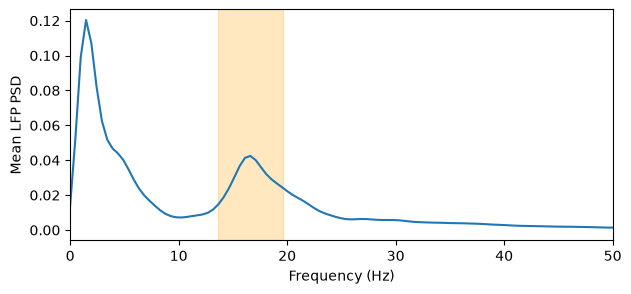

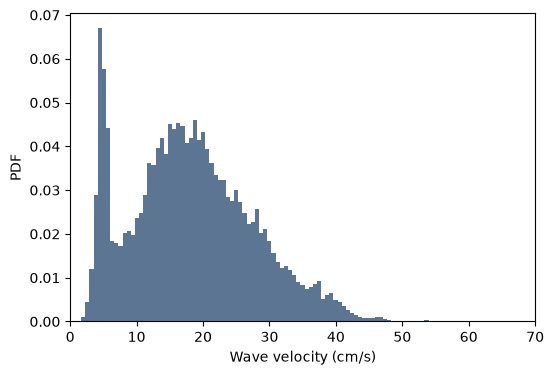

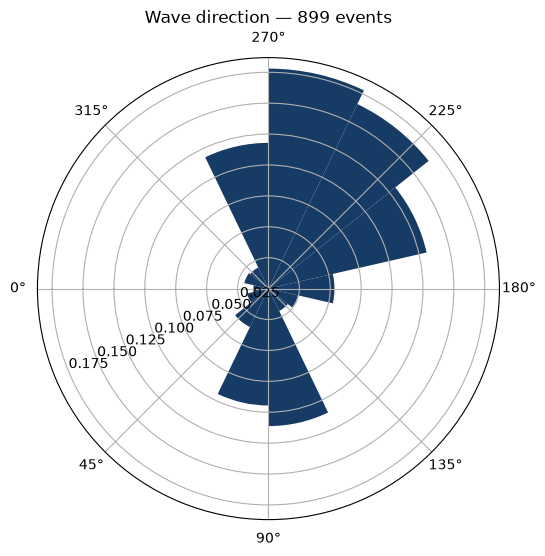

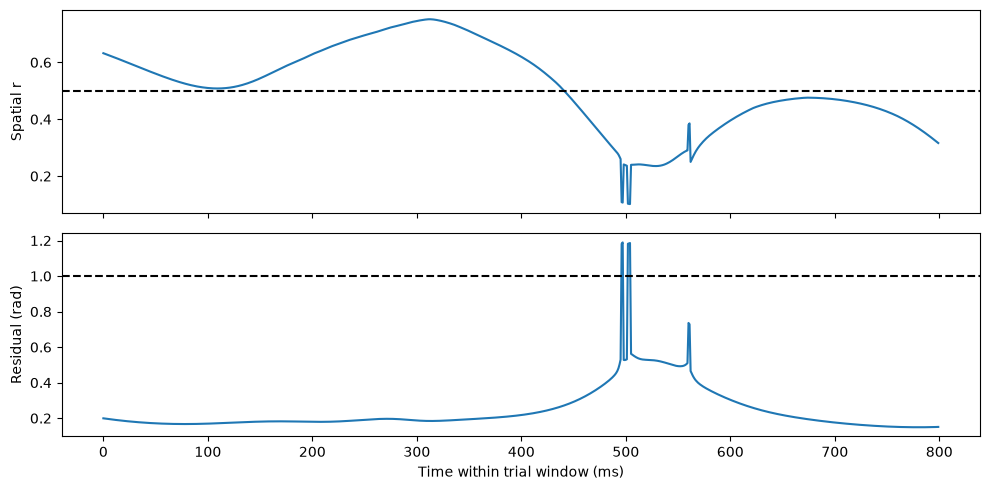

In [7]:
N_DIRECTION_BINS=14


fig,ax = plt.subplots(figsize=(7,3))
ax.plot(frequencies,mean_psd)
ax.axvspan(*band_hz,color="orange",alpha=.25)
ax.set(xlim=(0,50),xlabel="Frequency (Hz)",ylabel="Mean LFP PSD")
plt.show()

speeds = speed_results["all_speeds"]
if len(speeds):
    fig,ax = plt.subplots(figsize=(6,4))
    ax.hist(speeds,bins=100,density=True,color="#163B65",alpha=.7)
    ax.set(xlim=(0,70),xlabel="Wave velocity (cm/s)",ylabel="PDF")
    plt.show()
angles = Macaque_final["wave_directions"]
angles = angles[np.isfinite(angles)]
if len(angles):
    width = 2*np.pi/N_DIRECTION_BINS
    edges = np.arange(N_DIRECTION_BINS+1)*width-width/2
    wrapped = (angles+width/2)%(2*np.pi)-width/2
    counts,_ = np.histogram(wrapped,bins=edges)
    fig,ax = plt.subplots(figsize=(6,6),subplot_kw={"projection":"polar"})
    ax.bar(edges[:-1]+width/2,counts/len(angles),width=1*width,color="#163B65")
    ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
    ax.set_title(f"Wave direction — {len(angles)} events")
    ax.set_theta_offset(np.pi) #this is to align the caudal direction at the top of the plot - as in Fig 5

    ax.set_title(f"Wave direction — {len(angles)} events")

    fig.savefig("wave_directions.svg", format="svg",
                bbox_inches="tight", transparent=True)

    plt.show()

 
if trial_results:
    first = trial_results[0]
    t = np.arange(len(first["R"]))*LFP_SAMPLE_INTERVAL_MS
    fig,axes = plt.subplots(2,1,figsize=(10,5),sharex=True)
    axes[0].plot(t,first["R"]); axes[0].axhline(FIXED_R_THRESHOLD,color="k",ls="--")
    axes[0].set_ylabel("Spatial r")
    axes[1].plot(t,first["e_resid"]);  
    axes[1].set(xlabel="Time within trial window (ms)",ylabel="Residual (rad)")
    fig.tight_layout(); plt.show()


## Reading the result in the simulation notebook
Set `MACAQUE_FILE` to the printed path. With the retained defaults the filename is `Macaque_R_trials_100_DWfilter_4_r0.60_res0.30.mat`. If you choose `NUMBER_TRIALS = 10` and `BAND_HALF_WIDTH_HZ = 3.0`, it becomes `Macaque_R_trials_10_DWfilter_3_r0.60_res0.30.mat`.

The simulation notebook's default `SPEED_HISTOGRAM_UNIT = "frame"` reads `Macaque_final.all_speeds` correctly. For an **event versus event** comparison, its `plot_velocity_comparison()` must instead read `Macaque_final.event_mean_speeds` when `SPEED_HISTOGRAM_UNIT == "event"`; otherwise it compares simulation event means to data frame speeds.

Changing the cutoff can shorten or split events and consequently change their mean directions and speeds. Interpolation introduces spatial dependence; a fixed-r threshold is a coherence cutoff, not a significance test. Matching detection does not make the recording geometry, observation window, or preprocessing identical to simulations.
